# Week 4 — Baseline Model

Goal: Train an ordinary **Linear Regression** model to predict `ClosePrice`, evaluate **R² on the test set**, and record the baseline results.

Use the split-labeled export from `02_preprocessing.ipynb`: training set runs on January–March 2026 (27,974 sales) and tests on April 2026 (12,480 sales). November–December rows remain excluded from the model fit. Actual dates and counts are checked below rather than assumed.

The previous notebook selected this training window using Ridge validation MAE. We reuse that established split for comparability; we do not retune the window for Linear Regression. The previous Ridge MAE is not this model's result. April has already been inspected during earlier work, so this is a baseline comparison on an existing holdout, not a new untouched final evaluation.

Deliverables: This notebook `03_baseline_model.ipynb`.

## 1. Setup

Exporting split-labeled CSV from Week 3, `02_preprocessing.ipynb`.

In [1]:
#importing libraries
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "02_preprocessing.ipynb").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Start the kernel in the project root or notebooks directory.")

# Week 3's executable export uses data/raw, despite some narrative paths saying data/.
# Prefer that location; support the documented alternate location if needed.
candidates = [project_root / folder / "cleaned_single_family_sales_with_splits.csv"
              for folder in ("data/raw", "data")]
input_path = next((p for p in candidates if p.is_file()), None)
if input_path is None:
    raise FileNotFoundError("Run the split export in 02_preprocessing.ipynb first.")
print("Input:", input_path.relative_to(project_root))


Input: data/cleaned_single_family_sales_with_splits.csv


## 2. Load and verify the existing split

Use only the property and location predictors explicitly listed below. Exclude sale dates, listing identifiers, provenance, split labels, and training-window metadata from model inputs. Preserve ZIP codes as text. This notebook does not change the cleaning rules or make a new random split.


In [12]:
# features and target variable for model
NUMERIC_FEATURES = [
    "LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
    "GarageSpaces", "ParkingTotal", "Stories", "YearBuilt", "Latitude", "Longitude",
]
CATEGORICAL_FEATURES = ["City", "PostalCode"]
TARGET = "ClosePrice"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# PostalCose kept as string for categorical feature
input_sha256 = sha256_file(input_path)
sales = pd.read_csv(input_path, dtype={"ListingKeyNumeric": "string", "PostalCode": "string"})
required = {TARGET, "CloseDate", "ListingKeyNumeric", "split", "selected_training_months"}
missing = required - set(sales.columns)
if missing:
    raise ValueError(f"Required columns missing: {sorted(missing)}")
if not sales["split"].isin(["train", "test", "outside_training_window"]).all():
    raise ValueError("Unexpected or missing split labels; review the Week 3 export.")
sales["CloseDate"] = pd.to_datetime(sales["CloseDate"], errors="raise")
sales[TARGET] = pd.to_numeric(sales[TARGET], errors="raise")
assert sales["CloseDate"].notna().all(), "Missing sale dates."
assert sales["ListingKeyNumeric"].notna().all() and sales["ListingKeyNumeric"].is_unique
assert (np.isfinite(sales[TARGET]) & sales[TARGET].gt(0)).all()

numeric_features = [c for c in NUMERIC_FEATURES if c in sales]
categorical_features = [c for c in CATEGORICAL_FEATURES if c in sales]
for c in numeric_features:
    sales[c] = pd.to_numeric(sales[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
for c in categorical_features:
    sales[c] = sales[c].map(lambda v: str(v).strip() if pd.notna(v) and str(v).strip() else np.nan)

# spliting train/test data
train = sales.loc[sales["split"].eq("train")].copy()
test = sales.loc[sales["split"].eq("test")].copy()
assert len(train) > 0 and len(test) >= 2, "Need training data and at least two test rows."
assert train["CloseDate"].max() < test["CloseDate"].min(), "Split must be chronological."
months = sales["CloseDate"].dt.to_period("M")
test_month = months.max()
assert months.loc[test.index].eq(test_month).all()
assert sales.loc[months.eq(test_month), "split"].eq("test").all()
window_values = pd.to_numeric(sales["selected_training_months"], errors="raise").unique()
assert len(window_values) == 1 and np.isfinite(window_values[0])
window = int(window_values[0])
assert window > 0 and window == window_values[0]
expected_train = months.ge(test_month - window) & months.lt(test_month)
assert sales["split"].eq("train").equals(expected_train), "Split does not match selected window."
assert set(months.loc[train.index]) == set(pd.period_range(test_month - window, test_month - 1, freq="M"))
assert test[TARGET].nunique() > 1, "R² requires a nonconstant test target."

display(sales.groupby("split").agg(
    rows=(TARGET, "size"), first_sale=("CloseDate", "min"), last_sale=("CloseDate", "max")
))
print("Selected training window:", window, "months")


,rows,first_sale,last_sale
split,,,
outside_training_window,20150,2025-11-01,2025-12-31
test,12480,2026-04-01,2026-04-30
train,27974,2026-01-01,2026-03-31


Selected training window: 3 months


## 3. Fit Linear Regression

Fit numeric medians, missing indicators, scaling, and categorical encoding on **training data only** using a pipeline. Drop features entirely missing in training. Unseen test categories are ignored by the encoder. Drop the first categorical level to reduce redundant dummy columns; other correlated predictors can still make coefficients unstable.

The estimator is `LinearRegression` with an intercept, without Ridge regularization. Prices stay in dollars, so R² measures performance on the original target scale. Scaling does not change the target.


In [13]:
numeric_used = [c for c in numeric_features if train[c].notna().any()]
categorical_used = [c for c in categorical_features if train[c].notna().any()]
feature_columns = numeric_used + categorical_used
if not feature_columns:
    raise ValueError("No usable training predictors.")
print("Predictors:", feature_columns)
print("Entirely missing training features omitted:",
      sorted(set(numeric_features + categorical_features) - set(feature_columns)))

transformers = []
if numeric_used:
    transformers.append(("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_used))
if categorical_used:
    transformers.append(("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), categorical_used))

baseline_model = Pipeline([
    ("preprocess", ColumnTransformer(transformers)),
    ("regression", LinearRegression()),
])
X_train, y_train = train[feature_columns], train[TARGET]
X_test, y_test = test[feature_columns], test[TARGET]
baseline_model.fit(X_train, y_train)
print(f"Fitted Linear Regression on {len(train):,} sales.")


Predictors: ['LivingArea', 'LotSizeSquareFeet', 'BedroomsTotal', 'BathroomsTotalInteger', 'GarageSpaces', 'ParkingTotal', 'Stories', 'YearBuilt', 'Latitude', 'Longitude', 'City', 'PostalCode']
Entirely missing training features omitted: []
Fitted Linear Regression on 27,974 sales.


## 4. Evaluate and record baseline results

**Test R² is the required metric:** 1 is perfect; 0 matches the test-target mean benchmark; a negative score is worse than that benchmark. R² is not a percentage accuracy or a per-home error bound. MAE is included as the average absolute dollar error for context.

Also compare with a constant prediction equal to the **training** mean. Its test R² need not be zero because the train and test means can differ. Do not change features or the training window in response to April's scores; use earlier validation periods for further development.


In [8]:
test_predictions = baseline_model.predict(X_test)
assert np.isfinite(test_predictions).all()
test_r2 = float(r2_score(y_test, test_predictions))
test_mae = float(mean_absolute_error(y_test, test_predictions))
mean_predictions = np.full(len(y_test), float(y_train.mean()))
results = pd.DataFrame([
    {"model": "Linear Regression", "test_r2": test_r2, "test_mae_usd": test_mae},
    {"model": "Training-mean reference", "test_r2": float(r2_score(y_test, mean_predictions)),
     "test_mae_usd": float(mean_absolute_error(y_test, mean_predictions))},
])
display(results.style.format({"test_r2": "{:.4f}", "test_mae_usd": "${:,.2f}"}))
print(f"Week 4 baseline: test R² = {test_r2:.4f}; MAE = ${test_mae:,.2f} "
      f"across {len(test):,} sales in {test_month}.")
print("Negative price predictions:", int((test_predictions < 0).sum()))
print("Predictions are evaluated as produced; no post-hoc clipping is applied.")


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,model,test_r2,test_mae_usd
0,Linear Regression,0.6478,"$357,649.04"
1,Training-mean reference,-0.0016,"$751,222.46"


Week 4 baseline: test R² = 0.6478; MAE = $357,649.04 across 12,480 sales in 2026-04.
Negative price predictions: 234
Predictions are evaluated as produced; no post-hoc clipping is applied.


In [9]:
# Save aggregate results only. Rerunning replaces this baseline record.
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)
record = {
    "model": "LinearRegression", "target": TARGET, "target_units": "USD",
    "test_r2": test_r2, "test_mae_usd": test_mae,
    "comparison_results": results.to_dict(orient="records"),
    "train_rows": len(train), "test_rows": len(test),
    "train_first_sale": str(train["CloseDate"].min().date()),
    "train_last_sale": str(train["CloseDate"].max().date()),
    "test_month": str(test_month), "selected_training_months": window,
    "numeric_features": numeric_used, "categorical_features": categorical_used,
    "input_path": str(input_path.relative_to(project_root)), "input_sha256": input_sha256,
    "python_version": platform.python_version(),
    "package_versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn"]},
    "evaluation_note": "Existing holdout previously inspected during Week 3; window selected with Ridge validation MAE.",
}
results_path = results_dir / "03_baseline_results.json"
results_path.write_text(json.dumps(record, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print("Saved:", results_path.relative_to(project_root))


Saved: results/03_baseline_results.json


## 5. Visualize predictions and errors

All three plots use every test sale and prices in millions of dollars. Hexagonal bins show observation counts so overlapping homes remain visible. The dashed diagonal marks perfect predictions; the dashed zero line marks no error. **Error = predicted price − actual price:** positive errors are overestimates and negative errors are underestimates. The histogram uses a logarithmic count axis to show rare, large errors alongside common errors. No observations are clipped or removed.


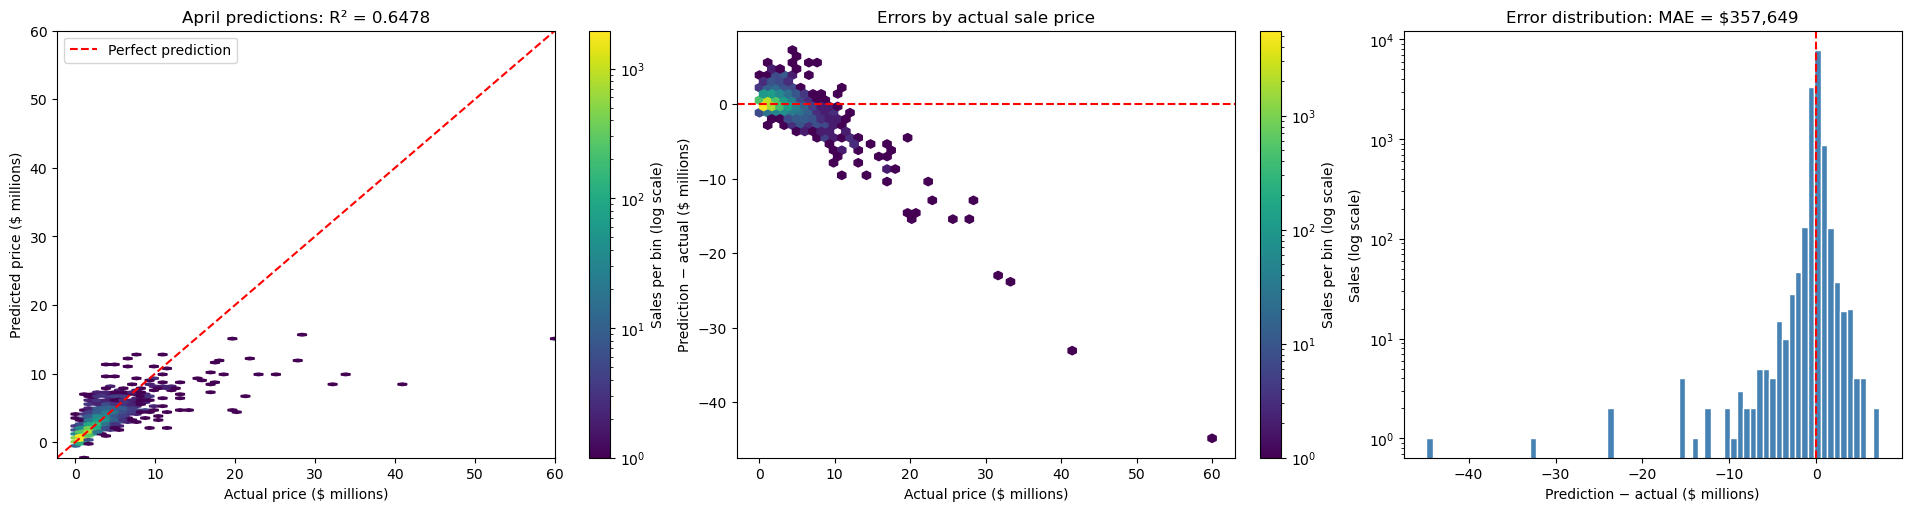

,Metric,USD
0,Mean signed error,"$-21,237.29"
1,Median absolute error,"$217,814.28"
2,90th percentile absolute error,"$661,113.67"


Positive mean signed error indicates average overprediction; negative indicates underprediction.


In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

actual = y_test.to_numpy(dtype=float)
predicted = np.asarray(test_predictions, dtype=float)
errors = predicted - actual
million = 1_000_000
fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)

counts = axes[0].hexbin(actual / million, predicted / million,
                        gridsize=55, mincnt=1, bins="log", cmap="viridis")
low = min(actual.min(), predicted.min()) / million
high = max(actual.max(), predicted.max()) / million
axes[0].plot([low, high], [low, high], "r--", linewidth=1.5, label="Perfect prediction")
axes[0].set(xlim=(low, high), ylim=(low, high),
            xlabel="Actual price ($ millions)", ylabel="Predicted price ($ millions)",
            title=f"April predictions: R² = {test_r2:.4f}")
axes[0].legend()
fig.colorbar(counts, ax=axes[0], label="Sales per bin (log scale)")

residual_counts = axes[1].hexbin(actual / million, errors / million,
                                 gridsize=55, mincnt=1, bins="log", cmap="viridis")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set(xlabel="Actual price ($ millions)", ylabel="Prediction − actual ($ millions)",
            title="Errors by actual sale price")
fig.colorbar(residual_counts, ax=axes[1], label="Sales per bin (log scale)")

axes[2].hist(errors / million, bins=70, color="steelblue", edgecolor="white", log=True)
axes[2].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[2].set(xlabel="Prediction − actual ($ millions)", ylabel="Sales (log scale)",
            title=f"Error distribution: MAE = ${test_mae:,.0f}")
plt.show()

error_summary = pd.DataFrame({
    "Metric": ["Mean signed error", "Median absolute error", "90th percentile absolute error"],
    "USD": [errors.mean(), np.median(np.abs(errors)), np.quantile(np.abs(errors), 0.90)],
})
display(error_summary.style.format({"USD": "${:,.2f}"}))
print("Positive mean signed error indicates average overprediction; negative indicates underprediction.")


## 6. Baseline takeaway

In the saved Week 4 run, Linear Regression trained on **27,974 January–March 2026 sales** and achieved **April test R² = 0.6478** across **12,480 sales**. This means it explains approximately **64.8% of the variation in April sale prices**, relative to predicting the April mean.

**Test MAE was $357,649.04**, the average absolute dollar error. These results are plausible as an initial baseline, but the error remains substantial. The model also generated **234 negative price predictions (1.88% of test sales)**, which are not realistic home prices. Predictions were evaluated without clipping. 

## Why the training-mean reference has R² = −0.0016

The reference predicts the **training mean** for every test home. Predicting the test mean would score exactly zero, but that mean is not available for future predictions. January–March's mean differs from April's, so using it produces a slightly larger squared error. A score of **−0.0016** means about **0.16% more total squared error** than the test-mean benchmark. This small negative score is expected when the means differ; it does not indicate a broken calculation. Linear Regression substantially improves on this constant reference.

## Limits and next steps
This is a useful first comparison point, not evidence of dependable pricing for every home. The evaluation covers retained sold homes in one month; accuracy for off-market homes or future months remains unverified. April was previously inspected, and the training window was selected using Ridge validation MAE.

To expand on this baseline and target the remaining 35.2% of unexplained price variation, future development will focus on the following geographic improvements:
- **Zip Code Coefficient Analysis**: We will extract and interpret the learned weights for individual zip codes to evaluate how the model penalizes or premiums specific localized boundaries. This helps verify if the high-cardinality categorical encoding is mapping spatial trends rationally.
- **Adding City-Level Categoricals**: We plan to introduce City as an additional categorical feature. Layering broader municipality data alongside the hyper-local zip codes will help the model capture macroeconomic regional trends and provide a stabilizing fallback for zip codes with sparse training data.

Moving forward, use earlier chronological validation folds for further model development, examine errors by price range and location, and obtain a new untouched holdout for a final performance claim.